# Numerical Standardization using StandardScaler
## Progress Review I — Individual Contribution

**Student ID:** IT25100429  
**Project:** Employee Resignation Prediction  
**Assigned Task:** Numerical feature standardization using StandardScaler  

---

### Purpose
This notebook demonstrates the core principles and implementation of numerical feature standardization:
- Why feature scaling is necessary for distance- and variance-sensitive machine learning algorithms.
- Selection of the approved numerical and ordinal features from the shared project contract (`configs/feature_contract.yaml`).
- Implementation of `StandardScaler` from `sklearn.preprocessing`.
- Before-and-after statistical and visual comparison of feature distributions.
- Interpretation of transformed results, standardization vs. min-max normalization, and data leakage prevention.

> **Note:** This is a standalone preprocessing demonstration designed to showcase standardization mechanics and viva concepts. In the group's formal cross-validation pipeline, scalers are strictly fitted only on training folds within each fold iteration (per `configs/feature_contract.yaml` and `src/models/runner.py`) to prevent data leakage.

In [1]:
# Import required libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Set float display format and plot styling
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

In [2]:
# Robust relative path detection
DATA_PATH = Path("data/raw/Extended_Employee_Performance_and_Productivity_Data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/raw/Extended_Employee_Performance_and_Productivity_Data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../../data/raw/Extended_Employee_Performance_and_Productivity_Data.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded successfully from: {DATA_PATH}")
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset loaded successfully from: ../../data/raw/Extended_Employee_Performance_and_Productivity_Data.csv
Dataset Shape: (100000, 20)


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0000,33,32,22,2,0,14,66,0,2.6300,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0000,34,34,13,14,100,12,61,2,1.7200,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0000,37,27,6,3,50,10,1,0,3.1700,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0000,52,10,28,12,100,10,0,1,1.8600,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0000,38,11,29,13,100,15,9,1,1.2500,False


In [3]:
# 13 approved numerical/ordinal predictors from configs/feature_contract.yaml
numerical_features = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score",
]

df_numeric = df[numerical_features].copy()
print(f"Selected {len(numerical_features)} numerical features across {len(df_numeric):,} records.")
df_numeric.head()

Selected 13 numerical features across 100,000 records.


,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
0,55,2,5,6750.0000,33,32,22,2,0,14,66,0,2.6300
1,29,0,5,7500.0000,34,34,13,14,100,12,61,2,1.7200
2,55,8,3,5850.0000,37,27,6,3,50,10,1,0,3.1700
3,48,7,2,4800.0000,52,10,28,12,100,10,0,1,1.8600
4,36,3,2,4800.0000,38,11,29,13,100,15,9,1,1.2500


In [4]:
# Display summary statistics of raw numerical features
raw_stats = df_numeric.describe().T
raw_stats

,count,mean,std,min,25%,50%,75%,max
Age,100000.0000,41.0294,11.2441,22.0000,31.0000,41.0000,51.0000,60.0000
Years_At_Company,100000.0000,4.4761,2.8693,0.0000,2.0000,4.0000,7.0000,10.0000
Performance_Score,100000.0000,2.9954,1.4147,1.0000,2.0000,3.0000,4.0000,5.0000
Monthly_Salary,100000.0000,6403.2110,1372.5087,3850.0000,5250.0000,6500.0000,7500.0000,9000.0000
Work_Hours_Per_Week,100000.0000,44.9569,8.9420,30.0000,37.0000,45.0000,53.0000,60.0000
Projects_Handled,100000.0000,24.4312,14.4696,0.0000,12.0000,24.0000,37.0000,49.0000
Overtime_Hours,100000.0000,14.5149,8.6640,0.0000,7.0000,15.0000,22.0000,29.0000
Sick_Days,100000.0000,7.0085,4.3316,0.0000,3.0000,7.0000,11.0000,14.0000
Remote_Work_Frequency,100000.0000,50.0905,35.3512,0.0000,25.0000,50.0000,75.0000,100.0000
Team_Size,100000.0000,10.0136,5.4954,1.0000,5.0000,10.0000,15.0000,19.0000


## Why Feature Scaling is Needed

In the raw dataset, features operate on vastly different scales and units:
- `Monthly_Salary` spans from $3,850 to $9,000 (standard deviation $\approx 1,372$).
- `Promotions` spans from 0 to 2 (standard deviation $\approx 0.82$).
- `Performance_Score` and `Employee_Satisfaction_Score` span from 1 to 5.

### Impact on Sensitive Algorithms
Distance- and variance-sensitive algorithms are severely distorted by unscaled features:
1. **Principal Component Analysis (PCA):** PCA seeks linear combinations that maximize variance. Because `Monthly_Salary` has a variance of $\sim 1.88 \times 10^6$ while `Promotions` has a variance of $\sim 0.67$, PCA on unscaled covariance matrices will treat `Monthly_Salary` as almost 3 million times more important, effectively dominating the first principal component regardless of actual predictive value.
2. **Logistic Regression & Linear Models:** Unscaled features create elongated, ill-conditioned cost surfaces for gradient descent, and $L_1/L_2$ regularization penalties disproportionately shrink features with naturally smaller numerical scales.
3. **Neural Architectures (e.g., FT-Transformer, TabNet):** Gradient propagation relies on normalized inputs for stable, balanced weight updates across feature embeddings.

### StandardScaler Formula
`StandardScaler` applies a z-score transformation to each feature independently:

$$z = \frac{x - \mu}{\sigma}$$

Where $\mu$ is the empirical mean and $\sigma$ is the empirical standard deviation. This rescales each feature to have a **mean of 0** and a **standard deviation of 1**.

### Scale-Invariance in Tree-Based Models
Tree-based algorithms (**CatBoost**, **XGBoost**, **LightGBM**, and **Explainable Boosting Machine (EBM)**) are **scale-invariant**. They make decisions by finding rank-order partition points ($x_j > \theta$). Because monotonic linear transformations do not change the rank ordering of values, scaling neither helps nor hurts tree splits.

In [5]:
# Fit and apply StandardScaler on numerical features
scaler = StandardScaler()
scaled_array = scaler.fit_transform(df_numeric)

# Reconstruct DataFrame with preserved column names and indices
df_scaled = pd.DataFrame(scaled_array, columns=numerical_features, index=df_numeric.index)
df_scaled.head()

,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
0,1.2425,-0.8629,1.4169,0.2527,-1.3372,0.5231,0.8639,-1.1563,-1.4169,0.7254,0.5709,-1.2253,-0.3207
1,-1.0698,-1.5600,1.4169,0.7991,-1.2253,0.6613,-0.1749,1.6141,1.4118,0.3615,0.3978,1.2260,-1.1116
2,1.2425,1.2281,0.0032,-0.4031,-0.8898,0.1775,-0.9828,-0.9254,-0.0026,-0.0025,-1.6790,-1.2253,0.1485
3,0.6199,0.8796,-0.7036,-1.1681,0.7876,-0.9974,1.5565,1.1523,1.4118,-0.0025,-1.7136,0.0003,-0.9899
4,-0.4473,-0.5144,-0.7036,-1.1681,-0.7780,-0.9282,1.6719,1.3832,1.4118,0.9074,-1.4021,0.0003,-1.5200


In [6]:
# Display summary statistics of scaled features focusing on mean, std, min, max
scaled_stats = df_scaled.describe().T[["mean", "std", "min", "max"]]
scaled_stats

,mean,std,min,max
Age,0.0000,1.0000,-1.6924,1.6872
Years_At_Company,-0.0000,1.0000,-1.5600,1.9252
Performance_Score,0.0000,1.0000,-1.4105,1.4169
Monthly_Salary,-0.0000,1.0000,-1.8603,1.8920
Work_Hours_Per_Week,0.0000,1.0000,-1.6727,1.6823
Projects_Handled,-0.0000,1.0000,-1.6885,1.6980
Overtime_Hours,0.0000,1.0000,-1.6753,1.6719
Sick_Days,0.0000,1.0000,-1.6180,1.6141
Remote_Work_Frequency,0.0000,1.0000,-1.4169,1.4118
Team_Size,-0.0000,1.0000,-1.6402,1.6353


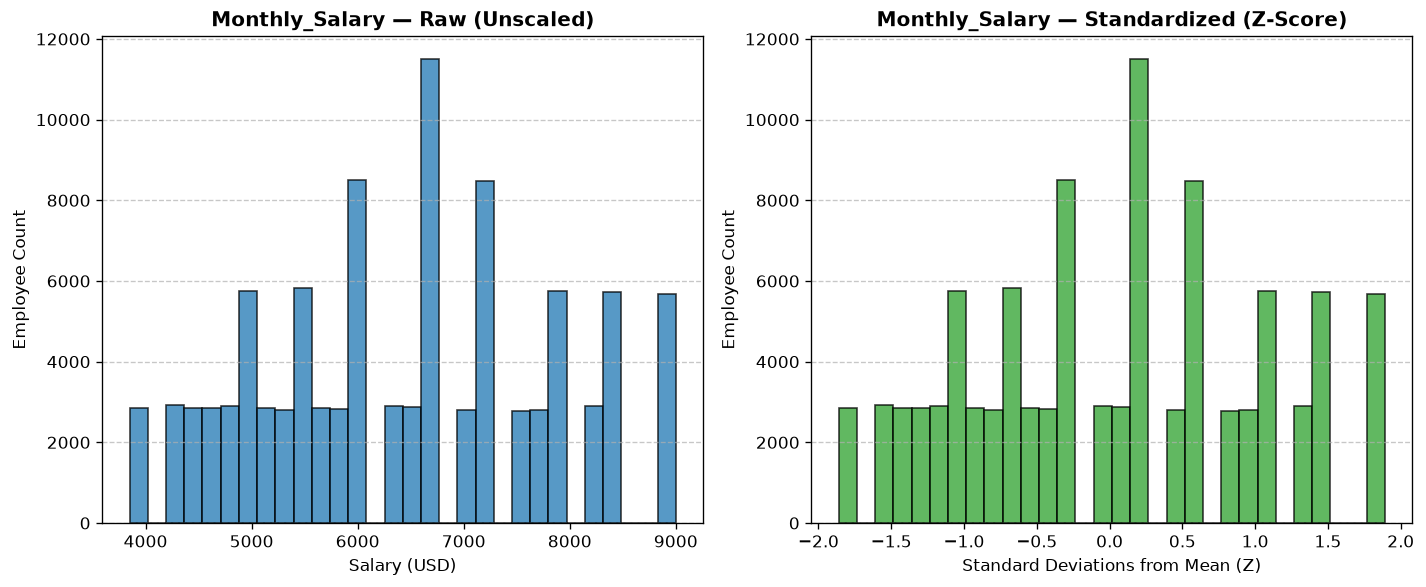

In [7]:
# Side-by-side histogram comparing Monthly_Salary before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw Monthly_Salary distribution
axes[0].hist(df_numeric["Monthly_Salary"], bins=30, color="#1f77b4", edgecolor="black", alpha=0.75)
axes[0].set_title("Monthly_Salary — Raw (Unscaled)", fontweight="bold")
axes[0].set_xlabel("Salary (USD)")
axes[0].set_ylabel("Employee Count")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Scaled Monthly_Salary distribution
axes[1].hist(df_scaled["Monthly_Salary"], bins=30, color="#2ca02c", edgecolor="black", alpha=0.75)
axes[1].set_title("Monthly_Salary — Standardized (Z-Score)", fontweight="bold")
axes[1].set_xlabel("Standard Deviations from Mean (Z)")
axes[1].set_ylabel("Employee Count")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

## Interpretation of Scaled Statistics & Relevance to PCA

### Key Statistical Findings
1. **Zero Mean ($\mu \approx 0$):** Every standardized feature now has an empirical mean on the order of $10^{-16}$, which is numerical zero.
2. **Unit Variance ($\sigma = 1$):** Each feature now has an exact standard deviation of 1.0. A value of $+1.5$ means the observation is exactly 1.5 standard deviations above the average.
3. **Shape Preservation:** As confirmed by the histograms in Cell 9, the shape, modality, and relative spread of the distribution remain identical before and after standardization. Z-score scaling is a linear affine shift ($z = a x + b$); it modifies the coordinates without warping the underlying distribution.

### Why Standardization is Essential Before PCA
- PCA computes orthogonal eigenvectors from the data's covariance matrix.
- If features are left unscaled, the variable with the largest original unit variance (`Monthly_Salary` in thousands of dollars) dominates the objective function $\max \text{Var}(w^T X)$.
- Standardizing to unit variance converts the covariance matrix into the **correlation matrix**, allowing PCA to extract components based on meaningful co-variation patterns across features rather than superficial unit magnitudes.

## Standardization vs. Min-Max Normalization & Leakage Prevention

### 1. Standardization vs. Min-Max Normalization

| Property | Standardization (Z-score) | Min-Max Normalization |
| :--- | :--- | :--- |
| **Formula** | $z = \frac{x - \mu}{\sigma}$ | $x_{\text{norm}} = \frac{x - x_{\text{min}}}{x_{\text{max}} - x_{\text{min}}}$ |
| **Output Range** | Unbounded (typically $[-3, +3]$) | Strictly bounded $[0, 1]$ |
| **Center & Spread** | $\mu = 0, \sigma = 1$ | Depends on min and max values |
| **Outlier Handling** | Robust: preserves outlier distances without compressing the bulk | Fragile: extreme outliers squash regular data into a tiny interval |
| **Preferred Use Cases** | PCA, Logistic Regression, Gaussian/RBF kernels, distance metrics | Image pixels ($[0, 255] \rightarrow [0, 1]$), bounded neural network activations |

*This notebook exclusively uses standardization because our project utilizes PCA and linear baselines on continuous demographic/workplace metrics where bounding to $[0, 1]$ is neither necessary nor desirable.*

### 2. Data Leakage Prevention
- In this isolated demonstration, the scaler is fitted on the provided data block to inspect whole-dataset mechanics.
- **Golden Rule in Real ML Pipelines:** In production and cross-validation workflows, a scaler must **NEVER** be fitted on the entire dataset prior to splitting.
- Scalers must call `fit_transform()` **strictly on the training fold** (computing $\mu_{\text{train}}$ and $\sigma_{\text{train}}$). Out-of-fold validation sets and holdout records must only receive `transform()` using those saved training parameters.
- Fitting across the whole dataset causes **data leakage** (future distribution statistics bleed into training), which artificially deflates generalization error and produces overly optimistic performance estimates.

## Conclusion & Viva Summary

### Key Takeaways
1. **Need for Scaling:** Raw workplace predictors differ by orders of magnitude (e.g., salary vs. promotion counts), creating massive variance imbalances.
2. **Feature Isolation:** Successfully selected and validated the 13 approved numerical/ordinal predictors in conformance with `configs/feature_contract.yaml`.
3. **Statistical Verification:** StandardScaler reliably transformed every predictor to $\mu \approx 0.0$ and $\sigma = 1.0$, while preserving the original distributional shape.
4. **Visual Proof:** Side-by-side histograms confirm scale realignment without altering distribution profile.
5. **Technique Selection:** Standardization is preferred over min-max normalization because it does not artificially compress outliers and directly standardizes the covariance matrix for PCA.
6. **Pipeline Scope & Model Sensitivity:** Scaling is not globally required for every model in our project:
   - **Requires Scaling:** The PCA demonstration (`notebooks/04a_pca_analysis.ipynb`) and the Logistic Regression benchmark.
   - **Scale-Invariant:** Tree ensembles (CatBoost, XGBoost, LightGBM, EBM) split on rank orders and do not require scaled inputs.